#  Ford GoBike Sharing System
# Exploratory Data Analysis (EDA)

## Project Overview

The Ford GoBike Sharing System is a public bike-sharing service that provides an affordable, convenient, and environmentally friendly mode of transportation. The company offers customers access to bikes across multiple stations, allowing users to rent and return bikes at different locations throughout the city.

This project focuses on analyzing the 2018 Ford GoBike trip data by combining all monthly datasets into a single dataset. The objective is to perform Exploratory Data Analysis (EDA) to understand customer riding behavior, identify travel patterns, evaluate service usage, and generate meaningful business insights that can support better decision-making.

#  Business Problem

Ford GoBike serves thousands of customers every day through its bike-sharing service. However, the company needs a better understanding of how customers use the service to improve operational efficiency and maximize business growth.

Some important business questions include:

- Which stations receive the highest number of trips?
- At what time are bikes used the most?
- Who uses the service more: Subscribers or Customers?
- Which customer groups generate the highest usage?
- Which locations require additional bikes?
- What customer behavior can help improve business decisions?

Without analyzing the available trip data, it becomes difficult to optimize bike availability, improve customer satisfaction, and increase overall profitability.

#  Business Objective

The primary objective of this project is to analyze the Ford GoBike trip data and understand how customers use the bike-sharing service.

Through Exploratory Data Analysis (EDA), this project aims to identify customer behavior, travel patterns, station demand, ride duration, and peak usage periods. The insights generated from this analysis will help the company improve operational efficiency, enhance customer satisfaction, optimize bike allocation, and increase business revenue.

### Business Objectives

- Understand customer riding behavior.
- Compare Subscribers and Customers.
- Identify the busiest start and end stations.
- Determine peak riding hours, weekdays, and months.
- Analyze ride duration across different customer groups.
- Study the influence of age and gender on bike usage.
- Discover high-demand locations requiring additional resources.
- Generate business recommendations to improve service quality and profitability.

#  Analysis Objectives

This Exploratory Data Analysis (EDA) will focus on the following objectives:

- Combine all monthly datasets into a single master dataset.
- Understand the dataset structure and variables.
- Perform data quality assessment.
- Handle missing values, duplicate records, and invalid data.
- Create new features that improve the analysis.
- Perform Univariate Analysis.
- Perform Bivariate Analysis.
- Perform Multivariate Analysis.
- Generate meaningful business insights from each visualization.
- Provide recommendations based on the analysis.

#  Tools and Libraries Used

### Programming Language
- Python

### Development Environment
- Jupyter Notebook

### Python Libraries

- Pandas
- NumPy
- Matplotlib
- Seaborn
- Glob
- Zipfile
- Warnings
- Datetime

These tools are used for data manipulation, cleaning, visualization, feature engineering, and exploratory data analysis.

# Dataset Description

The dataset contains monthly trip records of the Ford GoBike Sharing System for the year 2018. Each monthly dataset records detailed information about every bike trip, including ride duration, start and end stations, customer type, user demographics, and trip timings.

Since all monthly datasets share the same structure, they will be appended together to create one consolidated dataset for analysis.

The combined dataset will then undergo data cleaning, feature engineering, and exploratory data analysis to uncover meaningful business insights.

# Step 1: Import Required Libraries

In this step, we import the Python libraries required for data manipulation, file handling, visualization, and data analysis.

- **Pandas** is used for data manipulation and analysis.
- **NumPy** is used for numerical operations.
- **Matplotlib** and **Seaborn** are used for data visualization.
- **Glob** helps retrieve multiple files from a folder.
- **OS** is used for file path operations.
- **Warnings** suppresses unnecessary warning messages to keep the notebook clean.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import warnings
warnings.filterwarnings('ignore')
import matplotlib.ticker as mtick

%matplotlib inline

# Step 2: Load and Append the Monthly Datasets

The Ford GoBike dataset is provided as twelve monthly trip data files for the year 2018. Since all datasets have the same structure and columns, they can be combined into a single dataset using the `pd.concat()` function.

Appending the datasets into one master dataset allows us to perform data cleaning, feature engineering, and exploratory data analysis on the complete year's data instead of analyzing each month separately.

In [2]:
# Specify the folder path where all monthly datasets are stored

folder_path = r"C:\Users\sabil\Music\Ford-Go-bike sharing-20260711T114147Z-2-001\Ford-Go-bike sharing"

In [3]:
# Retrieve all CSV files

files = sorted(glob.glob(folder_path + "/*.csv"))

print("Total files found:", len(files))

Total files found: 12


In [4]:
# Read all datasets into a list

df_list = []

for file in files:
    df = pd.read_csv(file)
    df_list.append(df)

In [5]:
# Concatenate all datasets into a single DataFrame

bike_df = pd.concat(df_list, ignore_index=True)

print("All monthly datasets have been concatenated successfully.")

All monthly datasets have been concatenated successfully.


In [6]:
# Check the shape of the combined dataset

print("Number of Rows:", bike_df.shape[0])
print("Number of Columns:", bike_df.shape[1])

Number of Rows: 1863721
Number of Columns: 16


In [7]:
# Display the first five records

bike_df.head()

,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
0,75284,2018-01-31 22:52:35.2390,2018-02-01 19:47:19.8240,120.0,Mission Dolores Park,37.761420,-122.426435,285.0,Webster St at O'Farrell St,37.783521,-122.431158,2765,Subscriber,1986.0,Male,No
1,85422,2018-01-31 16:13:34.3510,2018-02-01 15:57:17.3100,15.0,San Francisco Ferry Building (Harry Bridges Pl...,37.795392,-122.394203,15.0,San Francisco Ferry Building (Harry Bridges Pl...,37.795392,-122.394203,2815,Customer,NaN,NaN,No
2,71576,2018-01-31 14:23:55.8890,2018-02-01 10:16:52.1160,304.0,Jackson St at 5th St,37.348759,-121.894798,296.0,5th St at Virginia St,37.325998,-121.877120,3039,Customer,1996.0,Male,No
3,61076,2018-01-31 14:53:23.5620,2018-02-01 07:51:20.5000,75.0,Market St at Franklin St,37.773793,-122.421239,47.0,4th St at Harrison St,37.780955,-122.399749,321,Customer,NaN,NaN,No
4,39966,2018-01-31 19:52:24.6670,2018-02-01 06:58:31.0530,74.0,Laguna St at Hayes St,37.776435,-122.426244,19.0,Post St at Kearny St,37.788975,-122.403452,617,Subscriber,1991.0,Male,No


# Step 3: Data Understanding

Before performing data cleaning and exploratory data analysis, it is important to understand the structure and quality of the dataset.

In this step, we will:

- Examine the size of the dataset.
- View the first and last few records.
- Check the column names and data types.
- Generate summary statistics.
- Identify missing values.
- Detect duplicate records.

This helps us identify any data quality issues that need to be addressed before analysis.

## 3.1 Check Dataset Shape

The shape of the dataset shows the total number of rows (observations) and columns (features). This gives us an overview of the dataset size.

In [8]:
bike_df.shape

(1863721, 16)

## 3.2 Display the First Five Records

The `head()` function displays the first five rows of the dataset. It helps us understand the structure, column names, and sample values.

In [9]:
bike_df.head()

,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
0,75284,2018-01-31 22:52:35.2390,2018-02-01 19:47:19.8240,120.0,Mission Dolores Park,37.761420,-122.426435,285.0,Webster St at O'Farrell St,37.783521,-122.431158,2765,Subscriber,1986.0,Male,No
1,85422,2018-01-31 16:13:34.3510,2018-02-01 15:57:17.3100,15.0,San Francisco Ferry Building (Harry Bridges Pl...,37.795392,-122.394203,15.0,San Francisco Ferry Building (Harry Bridges Pl...,37.795392,-122.394203,2815,Customer,NaN,NaN,No
2,71576,2018-01-31 14:23:55.8890,2018-02-01 10:16:52.1160,304.0,Jackson St at 5th St,37.348759,-121.894798,296.0,5th St at Virginia St,37.325998,-121.877120,3039,Customer,1996.0,Male,No
3,61076,2018-01-31 14:53:23.5620,2018-02-01 07:51:20.5000,75.0,Market St at Franklin St,37.773793,-122.421239,47.0,4th St at Harrison St,37.780955,-122.399749,321,Customer,NaN,NaN,No
4,39966,2018-01-31 19:52:24.6670,2018-02-01 06:58:31.0530,74.0,Laguna St at Hayes St,37.776435,-122.426244,19.0,Post St at Kearny St,37.788975,-122.403452,617,Subscriber,1991.0,Male,No


## 3.3 Display the Last Five Records

The `tail()` function displays the last five rows of the dataset. This helps verify that all monthly datasets were successfully concatenated.

In [10]:
bike_df.tail()

,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
1863716,473,2018-12-01 00:11:54.8110,2018-12-01 00:19:48.5470,345.0,Hubbell St at 16th St,37.766474,-122.398295,81.0,Berry St at 4th St,37.775880,-122.393170,3035,Subscriber,1982.0,Female,No
1863717,841,2018-12-01 00:02:48.7260,2018-12-01 00:16:49.7660,10.0,Washington St at Kearny St,37.795393,-122.404770,58.0,Market St at 10th St,37.776619,-122.417385,2034,Subscriber,1999.0,Female,No
1863718,260,2018-12-01 00:05:27.6150,2018-12-01 00:09:47.9560,245.0,Downtown Berkeley BART,37.870139,-122.268422,255.0,Virginia St at Shattuck Ave,37.876573,-122.269528,2243,Subscriber,1991.0,Male,No
1863719,292,2018-12-01 00:03:06.5490,2018-12-01 00:07:59.0800,93.0,4th St at Mission Bay Blvd S,37.770407,-122.391198,126.0,Esprit Park,37.761634,-122.390648,545,Subscriber,1963.0,Male,No
1863720,150,2018-12-01 00:03:05.7420,2018-12-01 00:05:36.0260,107.0,17th St at Dolores St,37.763015,-122.426497,119.0,18th St at Noe St,37.761047,-122.432642,4319,Subscriber,NaN,NaN,No


## 3.4 Display Column Names

Displaying the column names helps us understand the available features and identify the variables that will be used for analysis.

In [11]:
bike_df.columns

Index(['duration_sec', 'start_time', 'end_time', 'start_station_id',
       'start_station_name', 'start_station_latitude',
       'start_station_longitude', 'end_station_id', 'end_station_name',
       'end_station_latitude', 'end_station_longitude', 'bike_id', 'user_type',
       'member_birth_year', 'member_gender', 'bike_share_for_all_trip'],
      dtype='str')

## 3.5 Check Dataset Information

The `info()` function provides a summary of the dataset, including the number of non-null values, data types, and memory usage. This helps identify missing values and verify whether columns have appropriate data types.

In [12]:
bike_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1863721 entries, 0 to 1863720
Data columns (total 16 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   duration_sec             int64  
 1   start_time               str    
 2   end_time                 str    
 3   start_station_id         float64
 4   start_station_name       str    
 5   start_station_latitude   float64
 6   start_station_longitude  float64
 7   end_station_id           float64
 8   end_station_name         str    
 9   end_station_latitude     float64
 10  end_station_longitude    float64
 11  bike_id                  int64  
 12  user_type                str    
 13  member_birth_year        float64
 14  member_gender            str    
 15  bike_share_for_all_trip  str    
dtypes: float64(7), int64(2), str(7)
memory usage: 227.5 MB


## 3.6 Check Missing Values

Missing values are common in real-world datasets and can affect the accuracy of analysis. Before cleaning the dataset, it is important to identify columns containing missing values and determine the percentage of missing data.

This helps us decide whether to remove, replace, or retain missing values based on their impact on the analysis.

In [13]:
# Check missing values

bike_df.isnull().sum()

duration_sec                    0
start_time                      0
end_time                        0
start_station_id            11771
start_station_name          11771
start_station_latitude          0
start_station_longitude         0
end_station_id              11771
end_station_name            11771
end_station_latitude            0
end_station_longitude           0
bike_id                         0
user_type                       0
member_birth_year          110718
member_gender              110367
bike_share_for_all_trip         0
dtype: int64

In [14]:
# Calculate missing value percentage

missing_values = pd.DataFrame({
    'Missing Values': bike_df.isnull().sum(),
    'Percentage (%)': round((bike_df.isnull().sum()/len(bike_df))*100,2)
})

missing_values.sort_values(by='Percentage (%)', ascending=False)

,Missing Values,Percentage (%)
member_birth_year,110718,5.94
member_gender,110367,5.92
start_station_id,11771,0.63
start_station_name,11771,0.63
end_station_id,11771,0.63
end_station_name,11771,0.63
end_time,0,0.00
duration_sec,0,0.00
start_station_longitude,0,0.00
start_station_latitude,0,0.00


## 3.7 Check Duplicate Records

Duplicate records can lead to inaccurate analysis and biased results. Therefore, we check whether the dataset contains any duplicate rows before performing further analysis.

In [15]:
bike_df.duplicated().sum()

np.int64(0)

## 3.8 Check Unique Values

Understanding the number of unique values in categorical columns helps identify the diversity of data and detect any unexpected or inconsistent values that may require cleaning.

In [16]:
bike_df.nunique()

duration_sec                 16709
start_time                 1863584
end_time                   1863610
start_station_id               331
start_station_name             348
start_station_latitude         369
start_station_longitude        370
end_station_id                 331
end_station_name               348
end_station_latitude           370
end_station_longitude          371
bike_id                       5054
user_type                        2
member_birth_year               86
member_gender                    3
bike_share_for_all_trip          2
dtype: int64

# Step 4: Data Cleaning

Real-world datasets often contain missing values, duplicate records, incorrect data types, and invalid values that can affect the accuracy of analysis.

In this step, we will clean the dataset by identifying and handling data quality issues using appropriate techniques. The objective is to prepare a reliable dataset for feature engineering and exploratory data analysis.

In [17]:
bike_df = bike_df.dropna(subset=[
    'start_station_id',
    'start_station_name',
    'end_station_id',
    'end_station_name'
])

print("Rows after removing missing station information:", bike_df.shape[0])

Rows after removing missing station information: 1851950


## 4.2 Convert Date Columns

The `start_time` and `end_time` columns are currently stored as text (`object`) data types. To perform time-based analysis, such as extracting the ride hour, day, month, and weekday, these columns need to be converted into the `datetime` format.

Converting them to `datetime` also enables accurate calculations involving dates and times.

In [18]:
# Convert start_time and end_time to datetime format

bike_df['start_time'] = pd.to_datetime(bike_df['start_time'])
bike_df['end_time'] = pd.to_datetime(bike_df['end_time'])

# Verify the updated data types
bike_df[['start_time', 'end_time']].dtypes

start_time    datetime64[us]
end_time      datetime64[us]
dtype: object

## 4.3 Check Duplicate Records

Duplicate records can lead to incorrect analysis and biased results by counting the same trip more than once. Therefore, we check for duplicate records and remove them if any are present to ensure the dataset remains accurate and reliable.

In [19]:
# Check duplicate records

duplicate_rows = bike_df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_rows)

Total Duplicate Rows: 0


In [20]:
# Remove duplicate rows (if any)

bike_df.drop_duplicates(inplace=True)

print("Shape after removing duplicates:", bike_df.shape)

Shape after removing duplicates: (1851950, 16)


## 4.4 Validate Ride Duration

The ride duration should always be a positive value because every bike trip must take some amount of time. We check for zero or negative ride durations to identify any invalid records that may affect the analysis.

In [21]:
# Check for invalid ride duration

bike_df[bike_df['duration_sec'] <= 0]

,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip


## 4.5 Validate Member Birth Year

The member birth year is used to calculate customer age. We check for unrealistic birth years to ensure that age-related analyses are based on valid data.

For this project, birth years earlier than 1900 or later than 2018 are considered unrealistic and will be handled during data cleaning.

In [22]:
# Display the minimum and maximum birth year

print("Minimum Birth Year:", bike_df['member_birth_year'].min())
print("Maximum Birth Year:", bike_df['member_birth_year'].max())

Minimum Birth Year: 1881.0
Maximum Birth Year: 2000.0


In [23]:
# Check unrealistic birth years

bike_df[
    (bike_df['member_birth_year'] < 1900) |
    (bike_df['member_birth_year'] > 2018)
]

,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
548617,749,2018-05-14 06:46:47.550,2018-05-14 06:59:16.657,28.0,The Embarcadero at Bryant St,37.787168,-122.388098,81.0,Berry St at 4th St,37.775880,-122.393170,630,Subscriber,1889.0,Male,No
562505,654,2018-05-11 06:48:36.910,2018-05-11 06:59:31.647,28.0,The Embarcadero at Bryant St,37.787168,-122.388098,81.0,Berry St at 4th St,37.775880,-122.393170,1593,Subscriber,1889.0,Male,No
567868,546,2018-05-10 10:49:26.472,2018-05-10 10:58:32.579,81.0,Berry St at 4th St,37.775880,-122.393170,81.0,Berry St at 4th St,37.775880,-122.393170,1524,Subscriber,1889.0,Male,No
880583,824,2018-07-22 20:12:41.671,2018-07-22 20:26:26.447,107.0,17th St at Dolores St,37.763015,-122.426497,73.0,Pierce St at Haight St,37.771793,-122.433708,1128,Customer,1881.0,Male,No
882515,839,2018-07-22 14:10:11.007,2018-07-22 14:24:10.937,126.0,Esprit Park,37.761634,-122.390648,36.0,Folsom St at 3rd St,37.783830,-122.398870,4062,Customer,1881.0,Male,No
882646,376,2018-07-22 13:52:17.738,2018-07-22 13:58:34.517,355.0,23rd St at Tennessee St,37.755367,-122.388795,126.0,Esprit Park,37.761634,-122.390648,4062,Customer,1881.0,Male,No
882987,1331,2018-07-22 12:35:04.305,2018-07-22 12:57:15.319,109.0,17th St at Valencia St,37.763316,-122.421904,355.0,23rd St at Tennessee St,37.755367,-122.388795,4062,Customer,1881.0,Male,No
883138,4736,2018-07-22 11:13:26.307,2018-07-22 12:32:22.476,70.0,Central Ave at Fell St,37.773311,-122.444293,109.0,17th St at Valencia St,37.763316,-122.421904,2618,Customer,1881.0,Male,No
1085152,766,2018-08-21 12:32:52.208,2018-08-21 12:45:38.971,50.0,2nd St at Townsend St,37.780526,-122.390288,44.0,Civic Center/UN Plaza BART Station (Market St ...,37.781074,-122.411738,4319,Subscriber,1888.0,Other,No
1085201,2034,2018-08-21 11:55:20.227,2018-08-21 12:29:14.760,44.0,Civic Center/UN Plaza BART Station (Market St ...,37.781074,-122.411738,50.0,2nd St at Townsend St,37.780526,-122.390288,4319,Subscriber,1888.0,Other,No


## 4.6 Handle Invalid Birth Years

The `member_birth_year` column is used to calculate the age of each rider. During the data quality assessment, a few records were found with birth years earlier than 1900, resulting in unrealistic ages exceeding 118 years.

Since these records represent only a very small portion of the dataset and are likely due to data entry errors, they will be removed to ensure accurate age-based analysis.

In [24]:
# Remove records with unrealistic birth years (earlier than 1900)

bike_df = bike_df[
    (bike_df['member_birth_year'].isna()) |
    (bike_df['member_birth_year'] >= 1900)
]

print("Dataset Shape after removing invalid birth years:")
print(bike_df.shape)

Dataset Shape after removing invalid birth years:
(1851919, 16)


In [25]:
print("Minimum Birth Year:", bike_df['member_birth_year'].min())
print("Maximum Birth Year:", bike_df['member_birth_year'].max())

Minimum Birth Year: 1900.0
Maximum Birth Year: 2000.0


## 4.7 Handle Missing Gender Values

The `member_gender` column contains a small percentage of missing values. Instead of removing these records, the missing entries are labeled as **"Unknown"**.

This approach preserves valuable trip information while clearly identifying records where gender information is unavailable.

In [26]:
# Replace missing values in member_gender

bike_df['member_gender'] = bike_df['member_gender'].fillna('Unknown')

# Verify
bike_df['member_gender'].value_counts(dropna=False)

member_gender
Male       1279525
Female      435361
Unknown     110043
Other        26990
Name: count, dtype: int64

## 4.8 Verify Remaining Missing Values

After cleaning the dataset, we perform a final check to identify any remaining missing values. This confirms whether additional preprocessing is required before moving to feature engineering.

In [27]:
remaining_missing = pd.DataFrame({
    'Missing Values': bike_df.isnull().sum(),
    'Percentage (%)': round((bike_df.isnull().sum()/len(bike_df))*100, 2)
})

remaining_missing[remaining_missing['Missing Values'] > 0]

,Missing Values,Percentage (%)
member_birth_year,110394,5.96


### Data Cleaning Summary

The data cleaning process was completed to improve the quality and reliability of the dataset before analysis.

The following preprocessing steps were performed:

- Removed records with missing start and end station information.
- Converted `start_time` and `end_time` to datetime format.
- Verified that no duplicate records were present.
- Confirmed that there were no invalid ride durations.
- Removed records with unrealistic birth years (earlier than 1900).
- Replaced missing values in the `member_gender` column with **"Unknown"**.
- Retained missing values in `member_birth_year` because they represent a small percentage of the dataset and can be excluded only when performing age-related analysis.

The dataset is now cleaned and ready for feature engineering.

# Step 5: Feature Engineering

Feature engineering is the process of creating new variables from the existing dataset to improve analysis and extract meaningful insights.

The original dataset contains raw trip information such as ride duration, timestamps, and member birth year. In this step, new features will be derived from these columns to support time-based, demographic, and behavioral analysis.

The newly created features will help identify riding patterns, peak usage periods, customer age groups, and other important business insights.

## 5.1 Create Ride Duration (Minutes)

The ride duration is currently recorded in seconds. For easier interpretation and analysis, it is converted into minutes by dividing the duration (in seconds) by 60.

In [28]:
# Convert ride duration from seconds to minutes

bike_df['ride_duration_min'] = bike_df['duration_sec'] / 60

# Display first five values
bike_df[['duration_sec', 'ride_duration_min']].head()

,duration_sec,ride_duration_min
0,75284,1254.733333
1,85422,1423.700000
2,71576,1192.933333
3,61076,1017.933333
4,39966,666.100000


## 5.2 Extract Ride Year

The year is extracted from the ride start time. Although all trips belong to 2018, this feature ensures consistency and can support future datasets containing multiple years.

In [29]:
bike_df['ride_year'] = bike_df['start_time'].dt.year

bike_df['ride_year'].value_counts()

ride_year
2018    1851919
Name: count, dtype: int64

## 5.3 Extract Ride Month

The month is extracted from the ride start time to analyze monthly usage trends and seasonal riding patterns.

In [30]:
bike_df['ride_month'] = bike_df['start_time'].dt.month

bike_df['ride_month'].head()

0    1
1    1
2    1
3    1
4    1
Name: ride_month, dtype: int32

## 5.4 Create Month Name

To improve the readability of visualizations, the numeric month is converted into its corresponding month name.

In [31]:
bike_df['month_name'] = bike_df['start_time'].dt.month_name()

bike_df['month_name'].head()

0    January
1    January
2    January
3    January
4    January
Name: month_name, dtype: str

## 5.5 Extract Day of the Month

The day of the month is extracted from the ride start time. This feature can be used to study daily riding trends.

In [32]:
bike_df['ride_day'] = bike_df['start_time'].dt.day

bike_df['ride_day'].head()

0    31
1    31
2    31
3    31
4    31
Name: ride_day, dtype: int32

## 5.6 Extract Weekday Name

To understand riding patterns across the week, the weekday name is extracted from the ride start time. This feature will help identify the busiest weekdays and compare weekday versus weekend usage.

In [33]:
# Create weekday name

bike_df['day_name'] = bike_df['start_time'].dt.day_name()

bike_df['day_name'].head()

0    Wednesday
1    Wednesday
2    Wednesday
3    Wednesday
4    Wednesday
Name: day_name, dtype: str

## 5.7 Extract Ride Hour

The hour of the ride is extracted from the ride start time. This feature helps identify peak riding hours and understand customer travel behavior throughout the day.

In [34]:
# Create ride hour

bike_df['ride_hour'] = bike_df['start_time'].dt.hour

bike_df['ride_hour'].head()

0    22
1    16
2    14
3    14
4    19
Name: ride_hour, dtype: int32

## 5.8 Calculate Rider Age

The rider's age is calculated by subtracting the member's birth year from the dataset year (2018). This feature supports demographic analysis and helps understand which age groups use the bike-sharing service most frequently.

In [35]:
# Calculate rider age

bike_df['age'] = 2018 - bike_df['member_birth_year']

bike_df[['member_birth_year', 'age']].head()

,member_birth_year,age
0,1986.0,32.0
1,NaN,NaN
2,1996.0,22.0
3,NaN,NaN
4,1991.0,27.0


## 5.9 Create Age Groups

To simplify demographic analysis, riders are grouped into different age categories. This makes it easier to compare riding behavior across different age groups.

In [36]:
# Create age groups

bins = [0, 18, 25, 35, 45, 55, 100]
labels = ['Below 18', '18-25', '26-35', '36-45', '46-55', '56+']

bike_df['age_group'] = pd.cut(
    bike_df['age'],
    bins=bins,
    labels=labels
)

bike_df['age_group'].value_counts()

age_group
26-35       789490
36-45       389122
18-25       284441
46-55       185256
56+          86798
Below 18      5289
Name: count, dtype: int64

## 5.10 Create Time of Day

The ride hour is categorized into different periods of the day to better understand customer riding preferences. This feature helps identify whether most rides occur during the morning, afternoon, evening, or night.

In [37]:
# Create time of day

def time_period(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

bike_df['time_of_day'] = bike_df['ride_hour'].apply(time_period)

bike_df['time_of_day'].value_counts()

time_of_day
Morning      676447
Evening      557575
Afternoon    497628
Night        120269
Name: count, dtype: int64

### Feature Engineering Summary

To enhance the dataset for analysis, several new features were created from the existing variables.

The newly engineered features include:

- Ride Duration (Minutes)
- Ride Year
- Ride Month
- Month Name
- Ride Day
- Day Name
- Ride Hour
- Rider Age
- Age Group
- Time of Day

These derived features provide additional information that supports trend analysis, customer segmentation, and time-based insights during exploratory data analysis.

# Step 6: Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the characteristics of the dataset, identify patterns, detect trends, and uncover relationships between different variables.

The analysis is divided into three sections:

- **Univariate Analysis** – Examines the distribution of individual variables.
- **Bivariate Analysis** – Explores the relationship between two variables.
- **Multivariate Analysis** – Studies the interaction among multiple variables.

The insights obtained from these visualizations will help understand customer riding behavior, peak demand periods, user preferences, and business opportunities for improving the bike-sharing service.

## 6.1 Univariate Analysis

Univariate analysis focuses on examining one variable at a time to understand its individual characteristics and distribution. It provides a clear overview of the dataset by identifying patterns, frequencies, central tendencies, and variations within a single feature. This analysis serves as the foundation for understanding the overall structure of the data before exploring relationships between multiple variables.

## 6.1.1 Distribution of User Types

**Chart Type:** Univariate Analysis

**Plot Used:** Count Plot

This visualization displays the distribution of bike rides based on user membership type. It helps identify which category of riders contributes the most to the overall usage of the bike-sharing service.

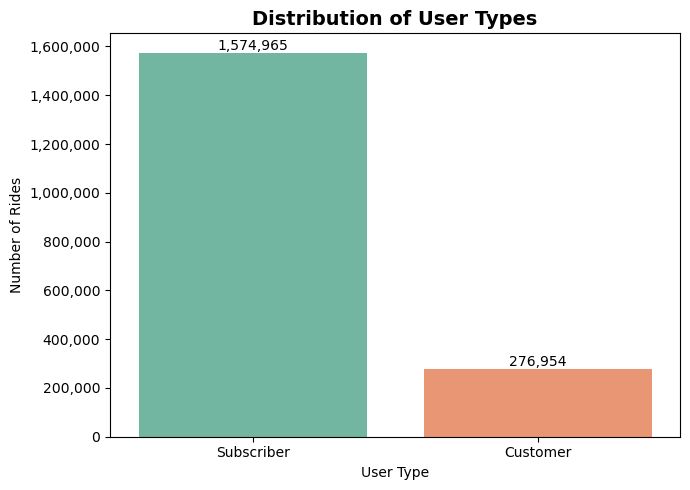

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

plt.figure(figsize=(7,5))

ax = sns.countplot(
    data=bike_df,
    x='user_type',
    palette='Set2'
)

plt.title("Distribution of User Types", fontsize=14, fontweight='bold')
plt.xlabel("User Type")
plt.ylabel("Number of Rides")

# Format y-axis with commas
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

# Add labels on top of bars
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center',
                va='bottom',
                fontsize=10)

plt.tight_layout()
plt.show()

### Observation

The visualization indicates that **Subscribers** account for the majority of bike rides.

- Subscriber: **1,574,965 rides**
- Customer: **276,954 rides**

This suggests that most users prefer subscription plans over one-time or casual rides, indicating strong customer retention.

### Business Insight

A large proportion of rides come from subscribers, demonstrating that recurring membership contributes significantly to service usage.

The company can focus on converting more casual customers into subscribers by introducing free trial memberships, referral programs, or discounted subscription plans. This strategy could increase customer loyalty and generate more consistent revenue.

## 6.1.2 Distribution of Member Gender

**Chart Type:** Univariate Analysis

**Plot Used:** Count Plot

This chart presents the distribution of riders by gender. It provides an overview of the demographic composition of users within the bike-sharing system.

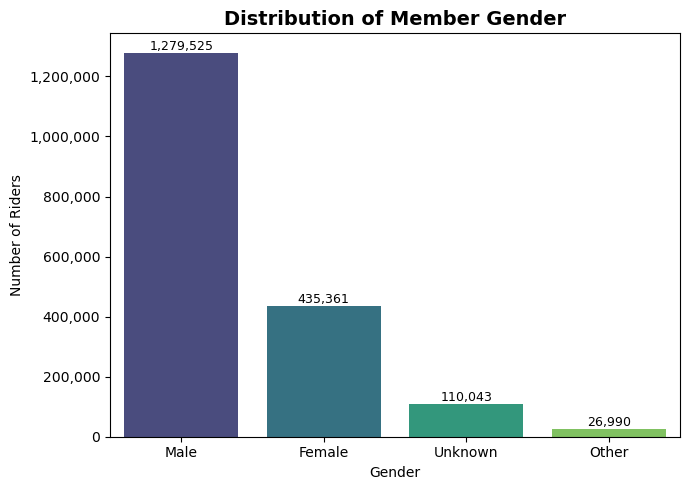

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

plt.figure(figsize=(7,5))

ax = sns.countplot(
    data=bike_df,
    x='member_gender',
    order=bike_df['member_gender'].value_counts().index,
    palette='viridis'
)

plt.title("Distribution of Member Gender", fontsize=14, fontweight='bold')
plt.xlabel("Gender")
plt.ylabel("Number of Riders")

# Format y-axis
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

# Add labels
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center',
                va='bottom',
                fontsize=9)

plt.tight_layout()
plt.show()

### Observation

The chart shows the distribution of riders across different gender categories. It helps identify which gender uses the bike-sharing service most frequently.

The visualization also includes riders whose gender information was unavailable and labeled as **"Unknown"**, ensuring that all records are represented in the analysis.

### Business Insight

Understanding the gender distribution enables the company to design more targeted marketing campaigns and improve customer engagement.

If one gender represents a significantly larger share of riders, the company can introduce promotional offers and awareness campaigns aimed at encouraging greater participation from underrepresented groups.

## 6.1.3 Distribution of Rider Age Groups

**Chart Type:** Univariate Analysis

**Plot Used:** Count Plot

This visualization illustrates the distribution of riders across different age groups. It helps identify the age categories that use the bike-sharing service most frequently.

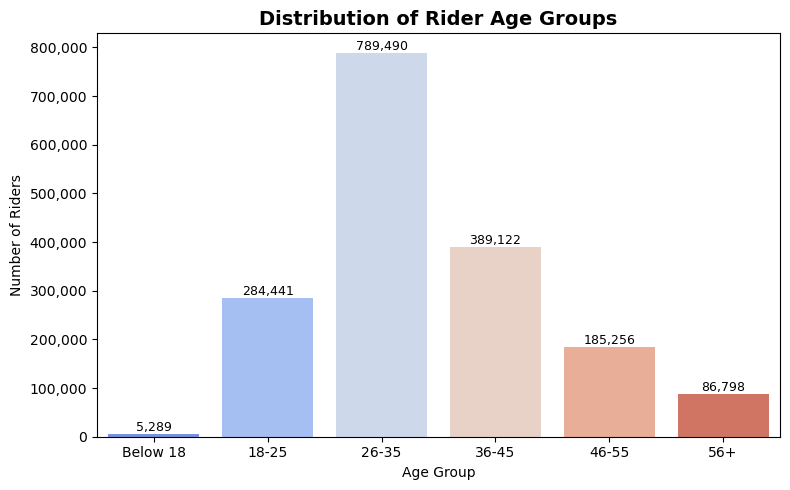

In [40]:
plt.figure(figsize=(8,5))

age_df = bike_df.dropna(subset=['age_group'])

ax = sns.countplot(
    data=age_df,
    x='age_group',
    order=['Below 18','18-25','26-35','36-45','46-55','56+'],
    palette='coolwarm'
)

plt.title("Distribution of Rider Age Groups", fontsize=14, fontweight='bold')
plt.xlabel("Age Group")
plt.ylabel("Number of Riders")

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center',
                va='bottom',
                fontsize=9)

plt.tight_layout()
plt.show()

### Observation

The visualization highlights the number of rides made by each age group, allowing us to identify the most active age segment among bike-sharing users.`

### Business Insight

The company can use age group insights to create age-specific membership plans, promotional campaigns, and customer engagement strategies. Understanding the dominant age segment also supports better service planning and targeted marketing efforts.

## 6.1.4 Distribution of Rides by Time of Day

**Chart Type:** Univariate Analysis

**Plot Used:** Count Plot

This chart shows how bike rides are distributed across different periods of the day, including Morning, Afternoon, Evening, and Night. It helps identify peak riding periods.

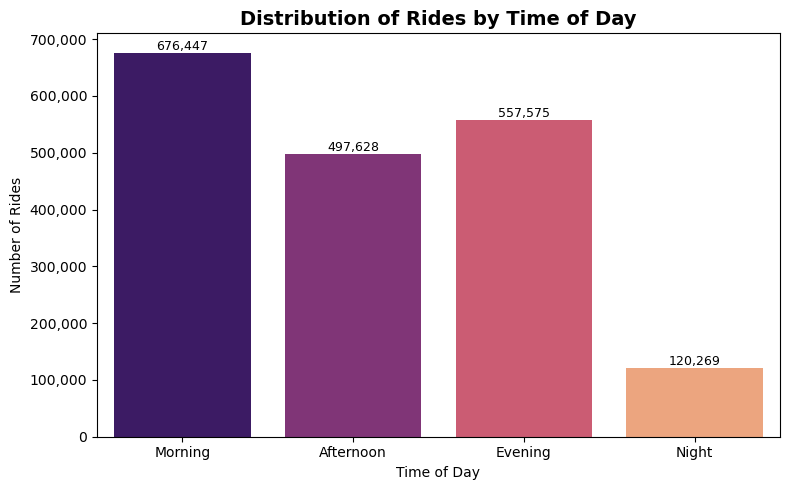

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

plt.figure(figsize=(8,5))

order = ['Morning', 'Afternoon', 'Evening', 'Night']

ax = sns.countplot(
    data=bike_df,
    x='time_of_day',
    order=order,
    palette='magma'
)

plt.title("Distribution of Rides by Time of Day", fontsize=14, fontweight='bold')
plt.xlabel("Time of Day")
plt.ylabel("Number of Rides")

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center',
                va='bottom',
                fontsize=9)

plt.tight_layout()
plt.show()

### Observation

The highest number of rides occurs during the **Morning**, followed by the **Evening**, while **Night** records the fewest rides. This indicates that most users rely on the bike-sharing service during regular commuting hours.

### Business Insight

The company should ensure that sufficient bikes are available during morning and evening peak periods to meet customer demand. Maintenance activities can be scheduled during low-demand hours, such as late at night, to minimize service disruption.

## 6.1.5 Distribution of Ride Duration

**Chart Type:** Univariate Analysis

**Plot Used:** Histogram

This histogram illustrates the distribution of ride durations in minutes. It helps understand the typical duration of trips taken by riders.

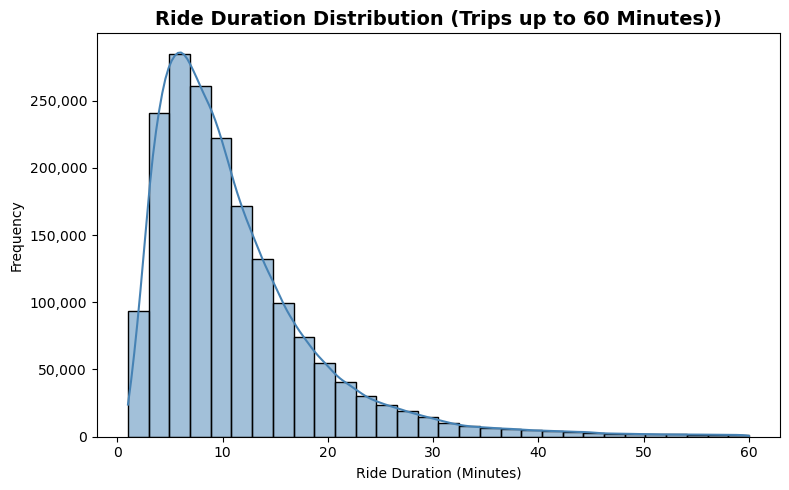

In [42]:
import matplotlib.ticker as ticker
plt.figure(figsize=(8,5))


sns.histplot(
    bike_df[bike_df['ride_duration_min'] <= 60]['ride_duration_min'],
    bins=30,
    kde=True,
    color='steelblue'
)

plt.title("Ride Duration Distribution (Trips up to 60 Minutes))", fontsize=14, fontweight='bold')
plt.xlabel("Ride Duration (Minutes)")
plt.ylabel("Frequency")

ax = plt.gca()
ax.ticklabel_format(style='plain', axis='y')
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

### Observation

The ride duration distribution is positively skewed, with the highest concentration of rides occurring between **5 and 15 minutes**. The frequency of rides decreases as the ride duration increases, and only a small proportion of trips last close to one hour.

### Business Insight

The results indicate that the bike-sharing service is primarily used for short-distance travel and daily commuting. The company should prioritize bike availability at high-demand stations to support frequent short trips, while also monitoring longer rides to better understand customer usage patterns.

# 6.2 Bivariate Analysis

Bivariate analysis is performed to study the relationship between two variables. It helps identify patterns, compare customer behavior, and understand how different factors influence bike-sharing usage.

The following visualizations focus on user behavior, ride duration, time trends, and demographic characteristics to support business decision-making.

## 6.2.1 Ride Duration by User Type

**Chart Type:** Bivariate Analysis

**Plot Used:** Box Plot

This visualization compares ride duration between Subscribers and Customers, helping identify differences in riding behavior between the two user groups.

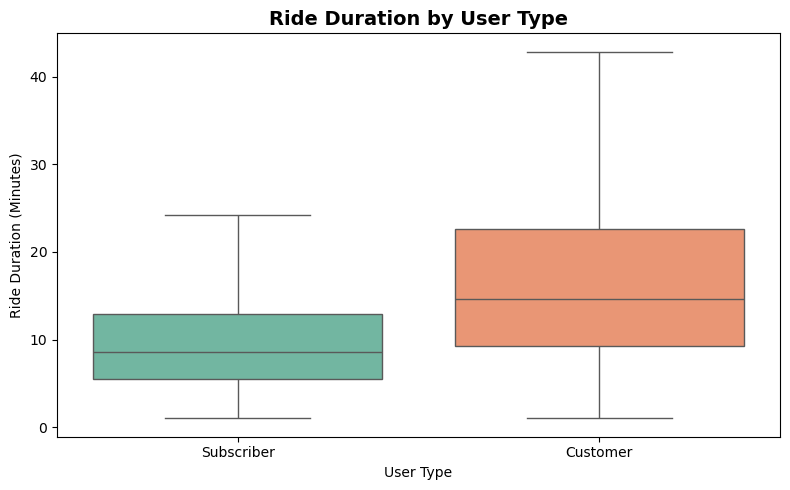

In [43]:
plt.figure(figsize=(8,5))

duration_df = bike_df[bike_df['ride_duration_min'] <= 60]

sns.boxplot(
    data=duration_df,
    x='user_type',
    y='ride_duration_min',
    palette='Set2',
    showfliers=False
)

plt.title("Ride Duration by User Type", fontsize=14, fontweight='bold')
plt.xlabel("User Type")
plt.ylabel("Ride Duration (Minutes)")

plt.tight_layout()
plt.show()

### Observation

Customers generally have longer ride durations than Subscribers. The median ride duration for Customers is noticeably higher, while Subscribers mostly take shorter trips.

### Business Insight

The results suggest that Subscribers mainly use bikes for regular commuting, whereas Customers are more likely to use them for leisure or occasional travel.

The company can encourage Customers to purchase subscription plans by offering trial memberships or discounts for frequent riders.

## 6.2.2 Ride Distribution by User Type and Time of Day

**Chart Type:** Bivariate Analysis

**Plot Used:** Grouped Count Plot

This chart compares ride frequency for each user type across different periods of the day. It helps understand when different categories of users are most active.

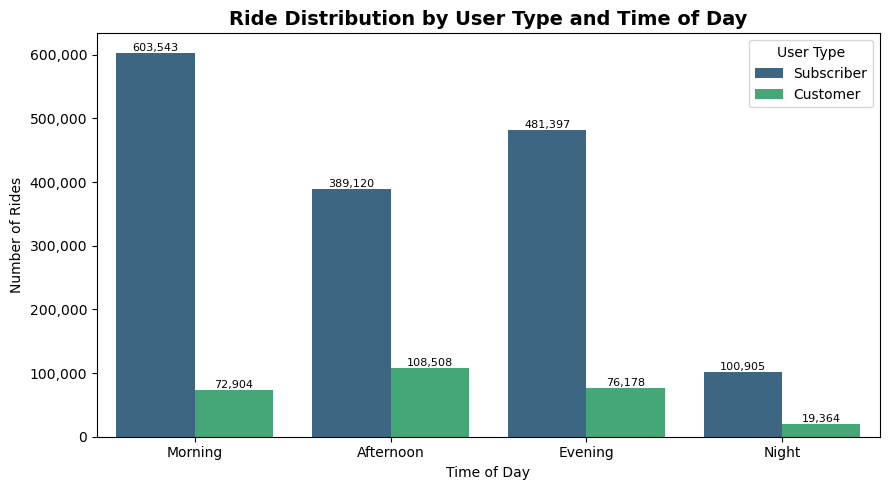

In [44]:
plt.figure(figsize=(9,5))

order = ['Morning','Afternoon','Evening','Night']

ax = sns.countplot(
    data=bike_df,
    x='time_of_day',
    hue='user_type',
    order=order,
    palette='viridis'
)

plt.title("Ride Distribution by User Type and Time of Day",
          fontsize=14,
          fontweight='bold')

plt.xlabel("Time of Day")
plt.ylabel("Number of Rides")

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', fontsize=8)

plt.legend(title="User Type")

plt.tight_layout()
plt.show()

### Observation

Subscriber rides are highest during the Morning and Evening, indicating strong commuting behavior. Customer rides are comparatively higher during the Afternoon, while Night records the fewest rides for both user groups.

### Business Insight

The company should ensure sufficient bike availability during morning and evening peak hours. Promotional campaigns and discounted rides during afternoon and night hours could help increase demand during off-peak periods.

## 6.2.3 Monthly Ride Trend

**Chart Type:** Bivariate Analysis

**Plot Used:** Bar Plot

This visualization displays the monthly distribution of bike rides, helping identify changes in ride demand throughout the year.

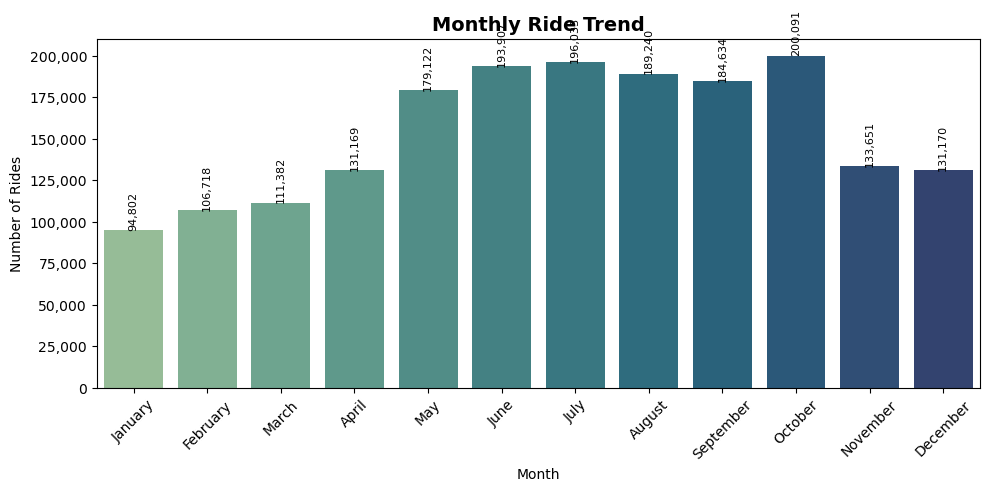

In [45]:
plt.figure(figsize=(10,5))

month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

ax = sns.countplot(
    data=bike_df,
    x='month_name',
    order=month_order,
    palette='crest'
)

plt.title("Monthly Ride Trend", fontsize=14, fontweight='bold')
plt.xlabel("Month")
plt.ylabel("Number of Rides")

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', fontsize=8, rotation=90)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The number of rides varies across the months, indicating seasonal fluctuations in bike-sharing usage. The busiest months represent periods of higher customer demand, while the quieter months indicate comparatively lower usage.

### Business Insight

Understanding monthly demand enables the company to plan bike availability, maintenance schedules, and marketing campaigns more effectively. During low-demand months, promotional offers can help increase customer engagement.

## 6.2.4 Ride Distribution by Day of the Week

**Chart Type:** Bivariate Analysis

**Plot Used:** Count Plot

This chart illustrates the number of rides recorded on each day of the week. It helps identify the busiest and least active days for bike usage.

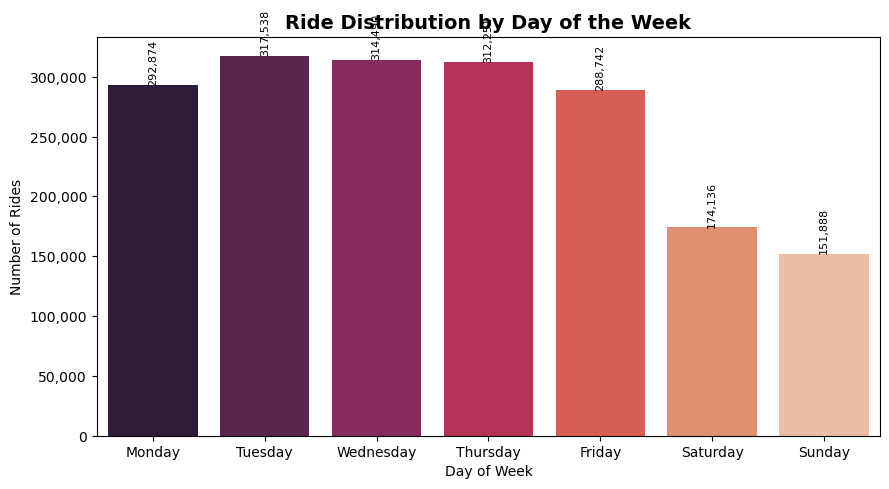

In [46]:
plt.figure(figsize=(9,5))

day_order = ['Monday','Tuesday','Wednesday',
             'Thursday','Friday',
             'Saturday','Sunday']

ax = sns.countplot(
    data=bike_df,
    x='day_name',
    order=day_order,
    palette='rocket'
)

plt.title("Ride Distribution by Day of the Week",
          fontsize=14,
          fontweight='bold')

plt.xlabel("Day of Week")
plt.ylabel("Number of Rides")

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', fontsize=8, rotation=90)

plt.tight_layout()
plt.show()

### Observation

Ride activity differs across the week, with certain weekdays recording noticeably higher usage than others. This reflects changing travel patterns between working days and weekends.

### Business Insight

Knowing the busiest days helps the company improve bike distribution and staffing. Lower-demand days can be targeted with special promotions to encourage additional rides.

## 6.2.5 Ride Duration by Gender

**Chart Type:** Bivariate Analysis

**Plot Used:** Box Plot

This visualization compares ride duration among different gender groups, helping identify variations in riding behavior across rider demographics.

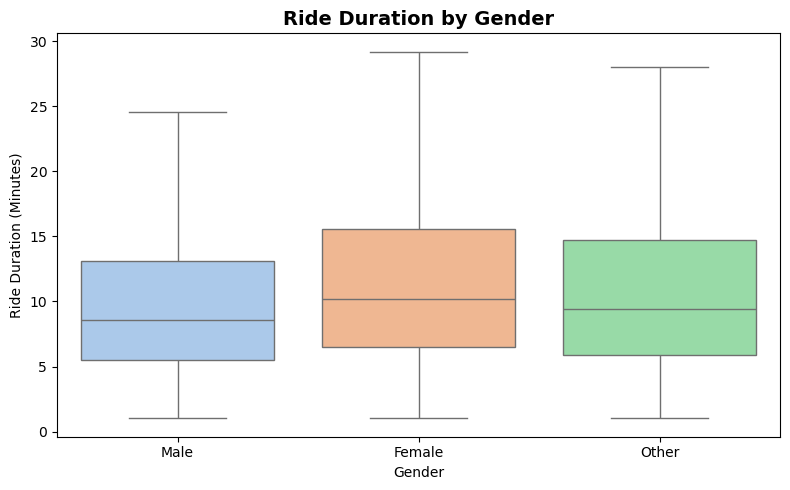

In [47]:
plt.figure(figsize=(8,5))

gender_df = bike_df[
    (bike_df['ride_duration_min'] <= 60) &
    (bike_df['member_gender'] != 'Unknown')
]

sns.boxplot(
    data=gender_df,
    x='member_gender',
    y='ride_duration_min',
    palette='pastel',
    showfliers=False
)

plt.title("Ride Duration by Gender", fontsize=14, fontweight='bold')
plt.xlabel("Gender")
plt.ylabel("Ride Duration (Minutes)")

plt.tight_layout()
plt.show()

### Observation

The ride duration distribution across gender groups allows comparison of riding behavior. Differences in the median and spread indicate whether any group tends to take longer trips than others.

### Business Insight

Gender-based riding patterns can help the company design inclusive marketing campaigns and improve services that appeal to a broader customer base.

## 6.3 Multivariate Analysis

Multivariate analysis explores the relationships among three or more variables simultaneously to gain a comprehensive understanding of complex data patterns. It helps identify interactions between multiple factors, uncover hidden trends, and evaluate how different variables collectively influence bike-sharing usage. This analysis provides deeper business insights that support data-driven decision-making and operational improvements.

## 6.3.1 Monthly Ride Trend by User Type (Multivariate)

**Chart Type:** Multivariate Analysis

**Plot Used:** Grouped Bar Plot

This chart compares monthly ride activity across different user types, providing a comprehensive view of seasonal demand and membership usage patterns.

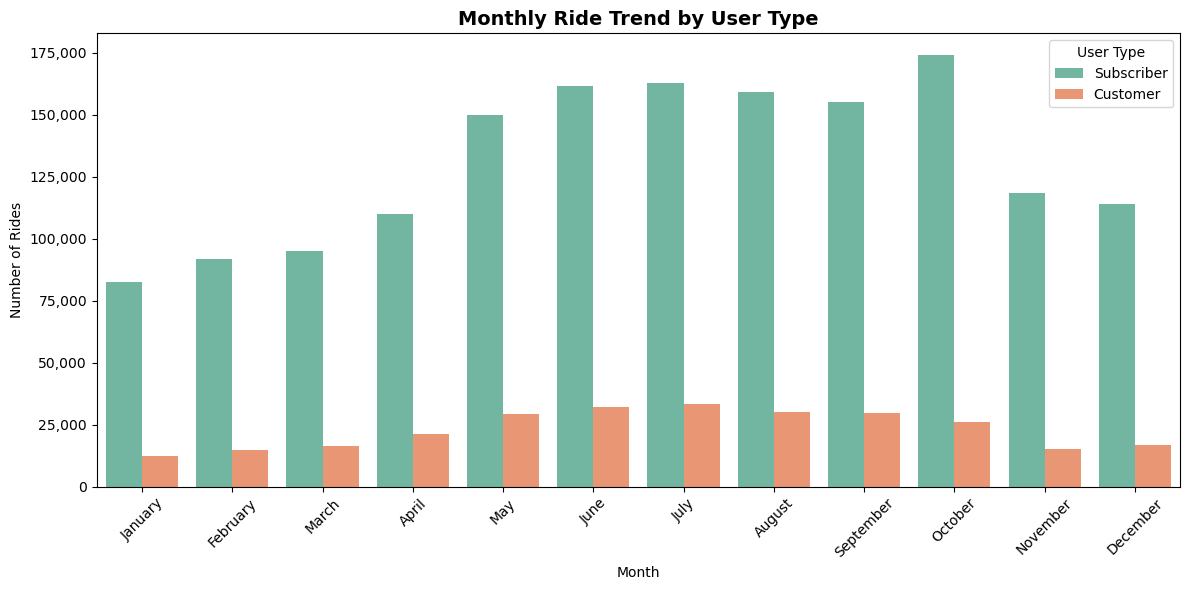

In [48]:
plt.figure(figsize=(12,6))

month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

ax = sns.countplot(
    data=bike_df,
    x='month_name',
    hue='user_type',
    order=month_order,
    palette='Set2'
)

plt.title("Monthly Ride Trend by User Type", fontsize=14, fontweight='bold')
plt.xlabel("Month")
plt.ylabel("Number of Rides")

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

plt.xticks(rotation=45)
plt.legend(title="User Type")

plt.tight_layout()
plt.show()

### Observation

Subscriber rides remain consistently higher than Customer rides throughout the year. Ride activity gradually increases from January, reaches its highest level around October, and then declines towards the end of the year for both user groups.

### Business Insight

The steady increase in rides during the middle of the year indicates higher customer demand, likely due to favorable weather and increased outdoor activities. The company should increase bike availability and maintenance resources during these peak months while using promotional campaigns to improve ridership during lower-demand months.

## 6.3.2 Ride Activity by Weekday and Time of Day

**Chart Type:** Multivariate Analysis

**Plot Used:** Heatmap

This heatmap visualizes ride frequency across weekdays and different times of the day. It highlights peak demand periods and weekly riding patterns.

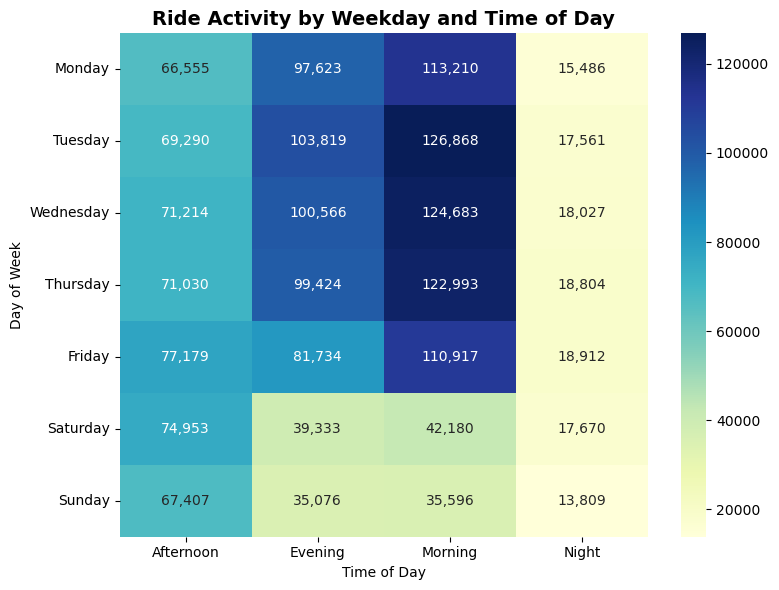

In [49]:
heatmap_data = pd.crosstab(
    bike_df['day_name'],
    bike_df['time_of_day']
)

heatmap_data = heatmap_data.reindex([
    'Monday','Tuesday','Wednesday',
    'Thursday','Friday',
    'Saturday','Sunday'
])

plt.figure(figsize=(8,6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=',',
    cmap='YlGnBu'
)

plt.title("Ride Activity by Weekday and Time of Day",
          fontsize=14,
          fontweight='bold')

plt.xlabel("Time of Day")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.show()

### Observation

The heatmap shows that Morning and Evening experience the highest ride activity on weekdays, especially from Tuesday to Friday. Weekend rides are comparatively lower during commuting hours, while Afternoon usage remains relatively consistent.

### Business Insight

The company should position more bikes at high-demand stations during weekday morning and evening hours to support commuter demand. Weekend promotions and leisure-focused campaigns can help increase bike usage during lower-demand periods.

## 6.3.3 Average Ride Duration by Month and User Type

**Chart Type:** Multivariate Analysis

**Plot Used:** Grouped Bar Plot

This visualization compares the average ride duration across months for different user types, helping identify seasonal variations in riding behavior.

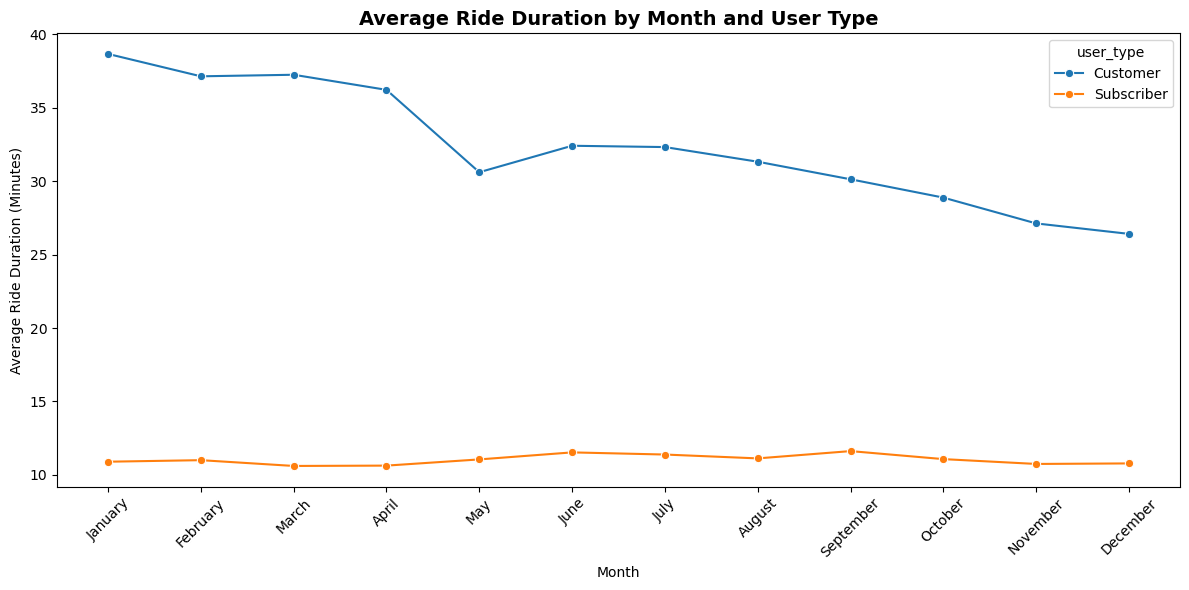

In [50]:
plt.figure(figsize=(12,6))

month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

avg_duration = bike_df.groupby(['month_name','user_type'])['ride_duration_min'].mean().reset_index()

avg_duration['month_name'] = pd.Categorical(
    avg_duration['month_name'],
    categories=month_order,
    ordered=True
)

avg_duration = avg_duration.sort_values('month_name')

sns.lineplot(
    data=avg_duration,
    x='month_name',
    y='ride_duration_min',
    hue='user_type',
    marker='o'
)

plt.title("Average Ride Duration by Month and User Type",
          fontsize=14,
          fontweight='bold')

plt.xlabel("Month")
plt.ylabel("Average Ride Duration (Minutes)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

Customers generally maintain a higher average ride duration than Subscribers throughout the year. The overall trend remains relatively stable, indicating consistent riding behavior across different seasons.

### Business Insight

Understanding seasonal ride duration patterns helps the company forecast demand and design seasonal membership offers or promotional campaigns targeted at different customer groups.

## 6.3.4 Gender Distribution by User Type

**Chart Type:** Multivariate Analysis

**Plot Used:** Grouped Count Plot

This chart compares gender distribution across different user types. It helps understand the demographic composition of Subscribers and Customers.

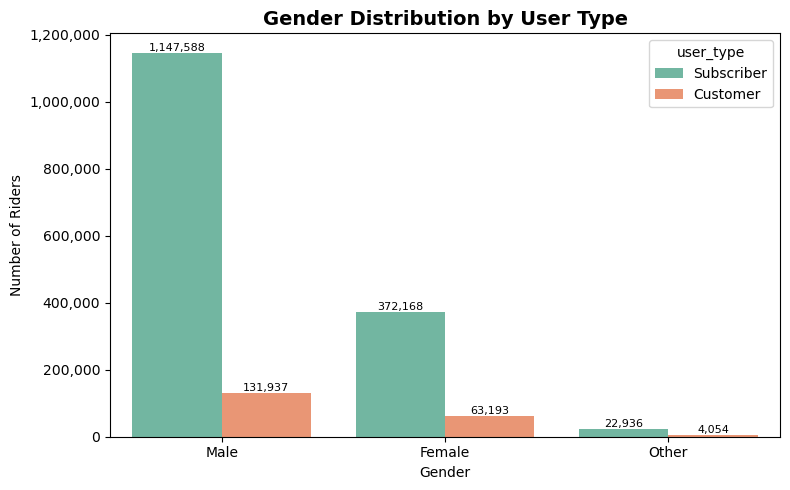

In [51]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=bike_df,
    x='member_gender',
    hue='user_type',
    order=['Male', 'Female', 'Other'],
    palette='Set2'
)

plt.title("Gender Distribution by User Type", fontsize=14, fontweight='bold')
plt.xlabel("Gender")
plt.ylabel("Number of Riders")

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', fontsize=8)

plt.tight_layout()
plt.show()

### Observation

The chart compares the number of male, female, and other riders within each user type. It highlights the demographic composition of Subscribers and Customers.

### Business Insight

Understanding the demographic profile of different user groups helps the company create targeted marketing campaigns and improve customer engagement strategies.

## 6.3.5 Average Ride Duration by Time of Day and User Type

**Chart Type:** Multivariate Analysis

**Plot Used:** Grouped Bar Plot

This visualization compares the average ride duration across different times of the day for each user type, helping identify differences in travel patterns.

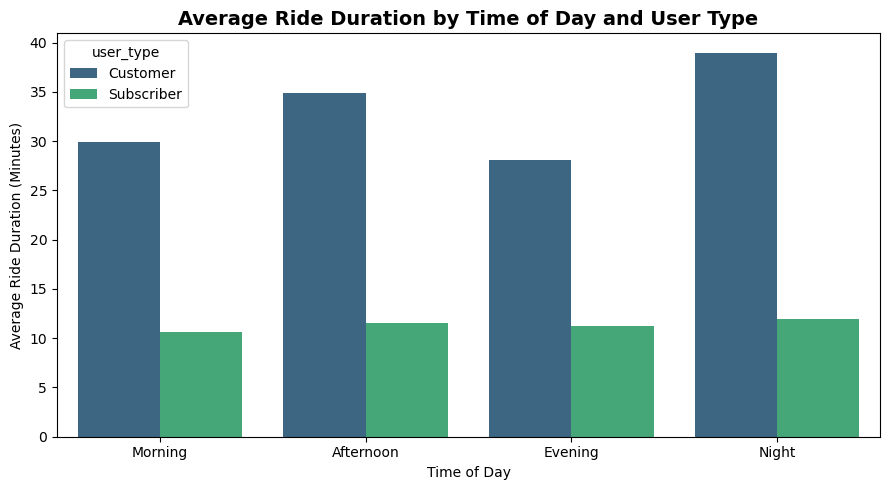

In [52]:
plt.figure(figsize=(9,5))

order = ['Morning', 'Afternoon', 'Evening', 'Night']

avg_time = bike_df.groupby(['time_of_day', 'user_type'])['ride_duration_min'].mean().reset_index()

avg_time['time_of_day'] = pd.Categorical(
    avg_time['time_of_day'],
    categories=order,
    ordered=True
)

avg_time = avg_time.sort_values('time_of_day')

sns.barplot(
    data=avg_time,
    x='time_of_day',
    y='ride_duration_min',
    hue='user_type',
    palette='viridis'
)

plt.title("Average Ride Duration by Time of Day and User Type",
          fontsize=14,
          fontweight='bold')

plt.xlabel("Time of Day")
plt.ylabel("Average Ride Duration (Minutes)")

plt.tight_layout()
plt.show()

### Observation

Customers consistently record a higher average ride duration than Subscribers across all times of the day. Ride duration remains relatively stable, with slight variations between different time periods.

### Business Insight

The findings indicate that Customers tend to use bikes for longer trips, while Subscribers mainly use them for shorter commuting journeys. The company can introduce flexible pricing or membership upgrades to encourage Customers to become regular Subscribers.

## 6.3.6 Top 10 Most Frequently Used Start Stations

**Chart Type:** Multivariate Analysis

**Plot Used:** Horizontal Bar Plot

This chart identifies the top 10 stations from which the highest number of bike rides begin. It helps locate major departure hubs with high rider demand.

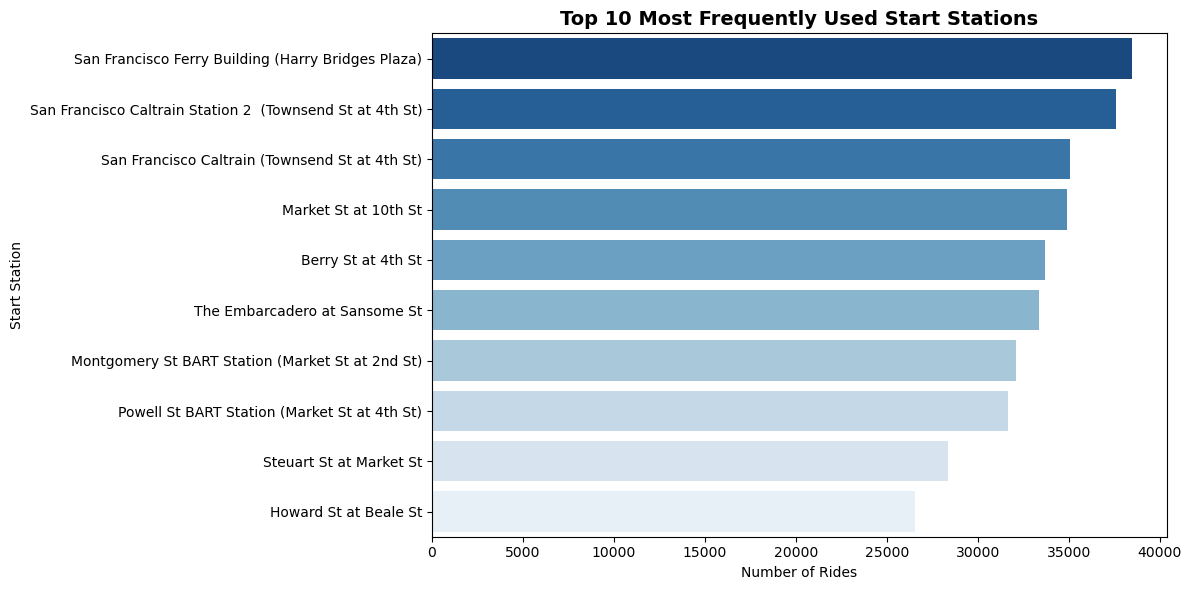

In [53]:
# Top 10 Start Stations
top_start = (
    bike_df['start_station_name']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_start.values,
    y=top_start.index,
    hue=top_start.index,
    legend=False,
    palette="Blues_r"
)

plt.title("Top 10 Most Frequently Used Start Stations",
          fontsize=14,
          fontweight='bold')

plt.xlabel("Number of Rides")
plt.ylabel("Start Station")

plt.tight_layout()
plt.show()

### Observation

The chart shows that only a few stations contribute to a large share of ride departures. These stations experience consistently high rider demand compared to other locations.

### Business Insight

High-demand start stations should always have an adequate number of bikes available, especially during peak commuting hours. Regular monitoring and timely bike redistribution at these stations can improve customer satisfaction and reduce bike shortages.

## 6.3.7 Top 10 Most Frequently Used End Stations

**Chart Type:** Multivariate Analysis

**Plot Used:** Horizontal Bar Plot

This visualization highlights the top 10 stations where the largest number of bike rides end. It helps identify important destination locations within the bike-sharing network.

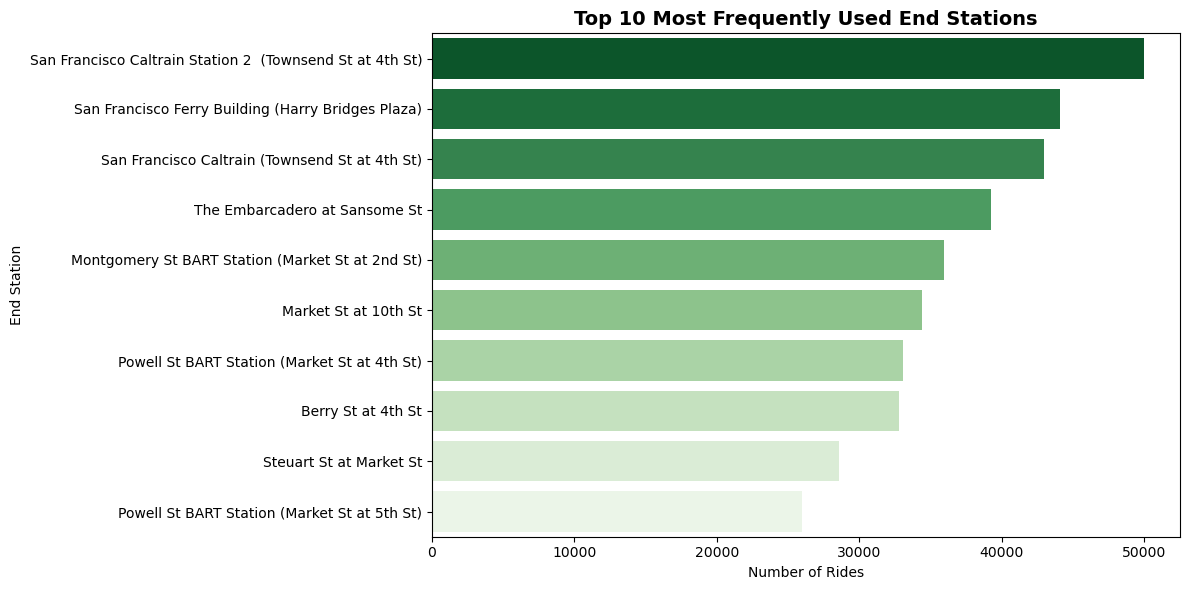

In [54]:
# Top 10 End Stations
top_end = (
    bike_df['end_station_name']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_end.values,
    y=top_end.index,
    hue=top_end.index,
    legend=False,
    palette="Greens_r"
)

plt.title("Top 10 Most Frequently Used End Stations",
          fontsize=14,
          fontweight='bold')

plt.xlabel("Number of Rides")
plt.ylabel("End Station")

plt.tight_layout()
plt.show()

### Observation

The chart highlights the stations where the largest number of rides end. These locations act as major destination points and receive significantly higher bike traffic than other stations.

### Business Insight

The company should regularly monitor these high-demand destination stations and redistribute bikes efficiently to prevent empty docks and improve bike availability across the network.

## 6.3.8 Correlation Analysis

**Chart Type:** Multivariate Analysis

**Plot Used:** Correlation Heatmap

This correlation heatmap illustrates the relationships among numerical variables in the dataset. It helps identify positive, negative, or weak correlations and supports a deeper understanding of rider behavior.

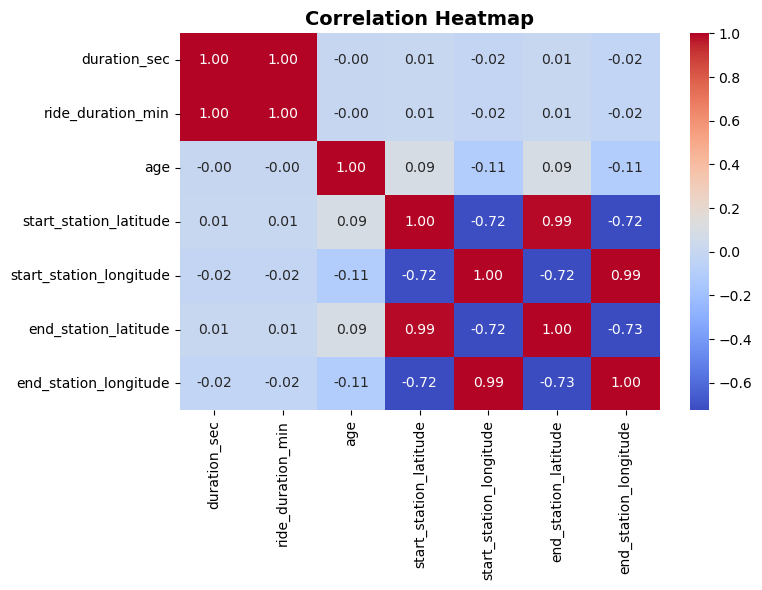

In [55]:
plt.figure(figsize=(8,6))

corr_data = bike_df[
    ['duration_sec',
     'ride_duration_min',
     'age',
     'start_station_latitude',
     'start_station_longitude',
     'end_station_latitude',
     'end_station_longitude']
].corr()

sns.heatmap(
    corr_data,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### Observation

The heatmap indicates that most numerical variables have weak to moderate correlations. Ride duration, rider age, and station coordinates do not exhibit strong linear relationships with one another.

### Business Insight

The weak correlations suggest that rider behavior is influenced by multiple factors rather than a single variable. Future analysis could incorporate additional information such as weather conditions, holidays, and local events to build more accurate predictive models.

# 7. Key Findings

Based on the exploratory data analysis, the following key findings were identified:

- Subscribers account for the majority of bike-sharing trips, indicating strong membership usage.
- Most riders belong to the young and middle-aged population, showing higher adoption among working-age users.
- Bike usage is highest during the Morning and Evening, reflecting daily commuting patterns.
- Ride duration varies across different user types, with Customers generally taking longer rides than Subscribers.
- Monthly ride activity changes throughout the year, indicating seasonal demand fluctuations.
- Weekday and time-of-day analysis highlights peak riding hours during business days.
- Certain start and end stations consistently experience higher ride volumes, making them major transportation hubs.
- Correlation analysis indicates meaningful relationships among numerical ride attributes that can support future predictive analysis.

# 8. Business Recommendations

Based on the analytical findings, the following recommendations are suggested:

1. Increase bike availability during Morning and Evening peak hours to meet higher commuter demand.

2. Improve bike distribution at high-demand start and end stations to reduce shortages and enhance service efficiency.

3. Introduce promotional campaigns during low-demand periods to encourage more bike usage.

4. Develop targeted marketing strategies for different customer segments based on age, gender, and membership type.

5. Encourage occasional Customers to become Subscribers by offering attractive membership benefits and discounts.

6. Regularly monitor station usage and ride trends to support operational planning and infrastructure improvements.

7. Continue using data analytics to monitor rider behavior and optimize decision-making for future business growth.

# 9. Conclusion

This project analyzed the Ford GoBike Sharing dataset using Python for data cleaning, feature engineering, and exploratory data analysis. Various univariate, bivariate, and multivariate visualizations were created to understand rider demographics, ride duration, travel patterns, seasonal trends, and station usage.

The analysis revealed valuable insights into customer behavior, peak demand periods, and station popularity. These findings can support better operational planning, resource allocation, and customer engagement strategies.

Overall, the project demonstrates how data analytics can transform large transportation datasets into meaningful business insights, enabling organizations to make informed, data-driven decisions and improve the efficiency of bike-sharing services.